# Gas Drag and Type-I Migration Comparison

This notebook compares gas-drag migration with Type-I migration timescales for a particle at a fixed orbital radius. The model is evaluated over a range of particle masses and eccentricities, and all figures are displayed directly in the notebook.

## 1. Setup

Import the plotting tools and the AccreDiff gas-drag/Type-I comparison model. The repository root is located from the current notebook working directory so that the notebook does not depend on `__file__`.

In [1]:
"""Parameters, plotting, and execution for the gas-drag/Type-I comparison."""
%matplotlib inline

from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

PROJECT_ROOT = None
for parent in [Path.cwd(), *Path.cwd().parents]:
    if (parent / "src" / "accrediff").exists():
        PROJECT_ROOT = parent
        sys.path.insert(0, str(parent / "src"))
        break

if PROJECT_ROOT is None:
    raise RuntimeError("Could not locate the AccreDiff repository root.")

from accrediff.gas_drag_type1_model import ComparisonConfig, build_comparison

HERE = PROJECT_ROOT / "examples" / "Expansion_module" / "GasDrag_Type1"
GAS_COLOR, TYPE1_COLOR = "#0072B2", "#D55E00"
LINESTYLES = {0.001: "-", 0.1: "--", 0.5: ":"}


## 2. Model Parameters

Define the orbital radius, the target particle mass used as a reference marker, and the eccentricities shown in the comparison plots.

In [2]:
# =========================================================
# 1. Parameters
# =========================================================
cfg = ComparisonConfig(
    radius_au=3.0,
    target_mass_mearth=2e-4,
    eccentricities=(0.001, 0.1, 0.5),
    sigma0_cgs = 2000,
)



## 3. Gas Drag and Type-I Torque Comparison

Compute the migration-time profiles and compare gas drag with the Type-I torque prescription. The figure uses logarithmic axes because the timescales span several orders of magnitude.

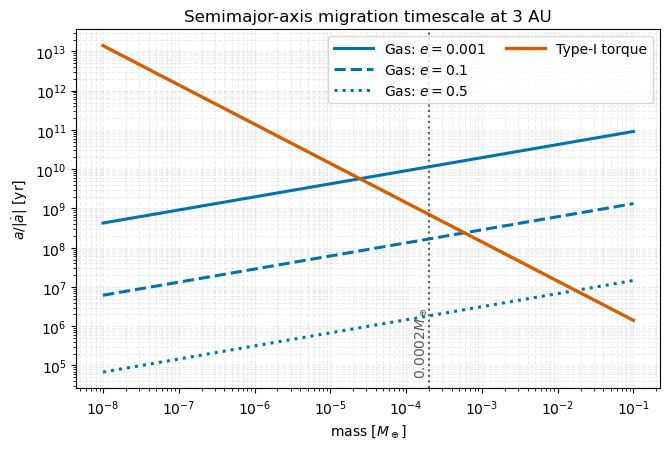

In [3]:
# =========================================================
# 2. Compute, plot, and report
# =========================================================
model = build_comparison(cfg)
result = model["comparison"].profile()
mass = result["mass_mearth"]

# Gas-only and Type-I torque comparison
fig, ax = plt.subplots(figsize=(6.8, 4.6))
for e in cfg.eccentricities:
    ax.loglog(
        mass,
        result["gas_ta_year"][e],
        color=GAS_COLOR,
        ls=LINESTYLES.get(e, "-"),
        lw=2.2,
    )
ax.loglog(
    mass,
    result["type1_torque_ta_year"],
    color=TYPE1_COLOR,
    lw=2.4,
)
ax.axvline(cfg.target_mass_mearth, color="0.35", ls=":")
ax.text(
    cfg.target_mass_mearth,
    0.03,
    fr"${cfg.target_mass_mearth:g}M_\oplus$",
    rotation=90,
    va="bottom",
    ha="right",
    color="0.35",
    transform=ax.get_xaxis_transform(),
)
ax.set(
    xlabel=r"mass [$M_\oplus$]",
    ylabel=r"$a/|\dot a|$ [yr]",
    title=f"Semimajor-axis migration timescale at {cfg.radius_au:g} AU",
)
ax.grid(which="both", alpha=0.22, ls="--")

gas_legend_handles = [
    Line2D(
        [0], [0],
        color=GAS_COLOR,
        ls=LINESTYLES.get(e, "-"),
        lw=2.2,
        label=fr"Gas: $e={e:g}$",
    )
    for e in cfg.eccentricities
]
type1_handle = Line2D(
    [0], [0],
    color=TYPE1_COLOR,
    lw=2.4,
    label="Type-I torque",
)
blank_handle = Line2D([], [], color="none")
ax.legend(
    handles=gas_legend_handles + [type1_handle, blank_handle, blank_handle],
    ncol=2,
    loc="upper right",
    columnspacing=1.5,
    handlelength=2.8,
)
fig.tight_layout()
plt.show()


## 4. Total Semimajor-Axis Evolution and Torque Crossings

Compare gas drag with the CN08 total evolution model. The printed crossing locations identify masses where the two migration timescales are equal.

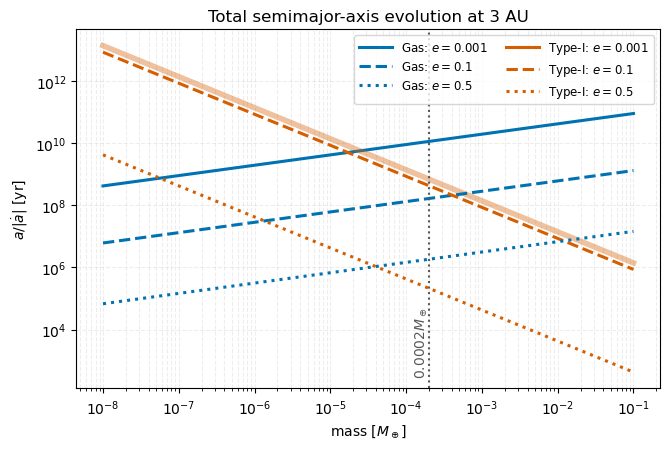

e=0.001: torque crossings=[np.float64(2.450632689665622e-05)]; CN08 crossings=[np.float64(2.4504985751768743e-05)]
e=0.1: torque crossings=[np.float64(0.0005861625096030474)]; CN08 crossings=[np.float64(0.00040781432351127793)]
e=0.5: torque crossings=[np.float64(0.017244516848713722)]; CN08 crossings=[np.float64(3.969046223350214e-05)]


In [4]:
# Gas and CN08 total comparison
fig, ax = plt.subplots(figsize=(6.8, 4.6))
for e in cfg.eccentricities:
    ax.loglog(
        mass,
        result["gas_ta_year"][e],
        color=GAS_COLOR,
        ls=LINESTYLES.get(e, "-"),
        lw=2.2,
    )
    # Low-e curves nearly overlap; a lighter, thicker line keeps both visible.
    lw, alpha = (4.0, 0.38) if e == 0.001 else (2.2, 1.0)
    ax.loglog(
        mass,
        result["cn08_total_ta_year"][e],
        color=TYPE1_COLOR,
        ls=LINESTYLES.get(e, "-"),
        lw=lw,
        alpha=alpha,
    )
ax.axvline(cfg.target_mass_mearth, color="0.35", ls=":")
ax.text(
    cfg.target_mass_mearth,
    0.03,
    fr"${cfg.target_mass_mearth:g}M_\oplus$",
    rotation=90,
    va="bottom",
    ha="right",
    color="0.35",
    transform=ax.get_xaxis_transform(),
)
ax.set(
    xlabel=r"mass [$M_\oplus$]",
    ylabel=r"$a/|\dot a|$ [yr]",
    title=f"Total semimajor-axis evolution at {cfg.radius_au:g} AU",
)
ax.grid(which="both", alpha=0.22, ls="--")

gas_legend_handles = [
    Line2D(
        [0], [0],
        color=GAS_COLOR,
        ls=LINESTYLES.get(e, "-"),
        lw=2.2,
        label=fr"Gas: $e={e:g}$",
    )
    for e in cfg.eccentricities
]
type1_legend_handles = [
    Line2D(
        [0], [0],
        color=TYPE1_COLOR,
        ls=LINESTYLES.get(e, "-"),
        lw=2.2,
        label=fr"Type-I: $e={e:g}$",
    )
    for e in cfg.eccentricities
]
ax.legend(
    handles=gas_legend_handles + type1_legend_handles,
    ncol=2,
    loc="upper right",
    columnspacing=1.5,
    handlelength=2.8,
    fontsize=8.5,
)
fig.tight_layout()
plt.show()

for e in cfg.eccentricities:
    torque_cross = model["comparison"].crossings(
        result["mass_mearth"], result["gas_ta_year"][e],
        result["type1_torque_ta_year"])
    total_cross = model["comparison"].crossings(
        result["mass_mearth"], result["gas_ta_year"][e],
        result["cn08_total_ta_year"][e])
    print(f"e={e:g}: torque crossings={torque_cross}; CN08 crossings={total_cross}")


In [5]:
from accrediff import Gas_ModelConfig, Gas_build_model

cfg = Gas_ModelConfig(
    Sigma0_cgs=1700.0,  # t=0、1 AU处的表面密度
    a_alpha1=1.0,
    a_alpha2=0.5,
    tau_decay_myr=1.0,
)

model = Gas_build_model(cfg)
disk = model["disk"]
units = model["units"]

a_au = 2.0
time_myr = 0.0
t_code = units.myr_to_code(time_myr)

sigma = disk.sigma_cgs(a_au, t_code)
print(f"Sigma_g({a_au:g} AU, {time_myr:g} Myr) = {sigma:.3f} g/cm²")

Sigma_g(2 AU, 0 Myr) = 743.491 g/cm²


## 5. Eccentricity-damping timescale versus mass

This section compares the local eccentricity-damping timescale

\[
\tau_e = \frac{e}{|\dot e|}
\]

for **gas drag only** and **Type-I damping only**.  Both branches use the same
`gas_migration.py` disk at 3 AU and at the initial disk epoch.  The comparison
is planar (`i=0`): gas drag is orbit-averaged from its instantaneous
`genga_style` acceleration, while Type-I uses the existing CN08 eccentricity
damping implementation.  The two effects are not added together.

The parameter block at the start of the next cell is self-contained so that
the radius, epoch, mass range, eccentricities, solid density, disk parameters,
and orbit-average resolution can be changed explicitly.


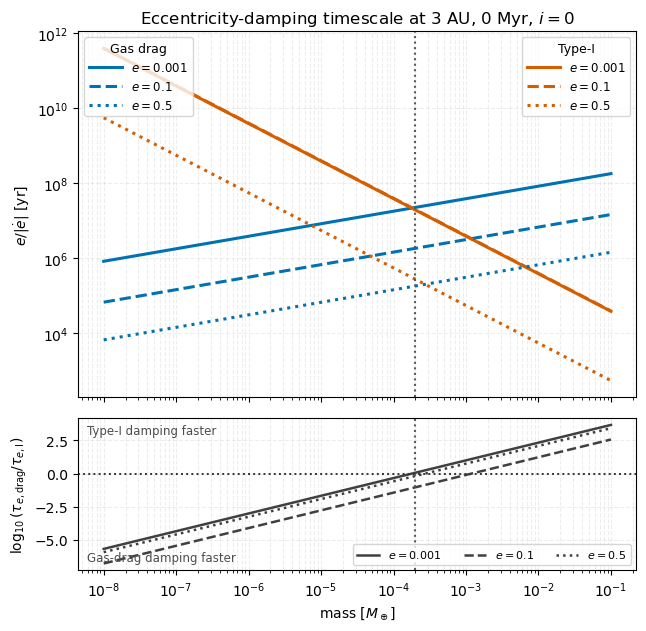

e=0.001: crossings=[np.float64(0.00017815128891899036)]; non-damping points (drag, Type-I)=(0, 0); 128-to-256 orbit-average change=2.55e-14
e=0.1: crossings=[np.float64(0.0011871202908543099)]; non-damping points (drag, Type-I)=(0, 0); 128-to-256 orbit-average change=2.54e-16
e=0.5: crossings=[np.float64(0.00027285588078241696)]; non-damping points (drag, Type-I)=(0, 0); 128-to-256 orbit-average change=4.84e-16


In [6]:
# =========================================================
# 3. Gas-only and Type-I-only eccentricity damping
# =========================================================
import numpy as np

# Make the example-layer drag modules importable even when the notebook is
# launched from the repository root instead of this notebook's directory.
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))

from accrediff.gas_drag_type1_model import (
    AerodynamicDragModel,
    TimescaleComparison,
    TypeIAdapter,
)
from paper_fig2_disk import GasMigrationDiskAdapter
from paper_fig2_drag import (
    AerodynamicDrag,
    GasFlowPolicy,
    MEARTH_G,
    Planetesimal,
)
from paper_fig2_orbit_average import orbit_averaged_rates

# ---- Explicit parameters for this comparison ----
ecc_cfg = ComparisonConfig(
    radius_au=3.0,
    time_myr=0.0,
    mass_min_mearth=1e-8,
    mass_max_mearth=1e-1,
    n_mass=500,
    target_mass_mearth=2e-4,
    eccentricities=(0.001, 0.1, 0.5),
    inclination_over_e=0.0,       # planar comparison: i = 0
    solid_density_cgs=2.0,
    drag_coefficient=0.5,
    sigma0_cgs=2000.0,
    tau_decay_myr=1.0,
    a_alpha1=1.0,
    a_alpha2=0.5,
    beta=0.25,
    h1=0.0335743,
)
ECC_ORBIT_SAMPLES = 128

ecc_mass = ecc_cfg.mass_grid_mearth
ecc_type1 = TypeIAdapter(ecc_cfg)
ecc_drag_analytic = AerodynamicDragModel(ecc_cfg)
ecc_tau_drag_year = {e: np.empty_like(ecc_mass) for e in ecc_cfg.eccentricities}
ecc_tau_type1_year = {e: np.empty_like(ecc_mass) for e in ecc_cfg.eccentricities}
ecc_de_drag_per_myr = {e: np.empty_like(ecc_mass) for e in ecc_cfg.eccentricities}
ecc_de_type1_per_code = {e: np.empty_like(ecc_mass) for e in ecc_cfg.eccentricities}

# The disk structure does not depend on planetesimal mass.  Construct it once
# from the same Type-I factory used below, then expose it to the drag module.
ecc_reference_model = ecc_type1.build_model(ecc_cfg.target_mass_mearth)
ecc_units = ecc_reference_model["units"]
ecc_disk = GasMigrationDiskAdapter(ecc_reference_model["disk"], ecc_units)

for j, mass_mearth in enumerate(ecc_mass):
    # Fixed material density makes physical radius scale as mass**(1/3).
    mass_g = mass_mearth * MEARTH_G
    radius_cm = (3.0 * mass_g / (4.0 * np.pi * ecc_cfg.solid_density_cgs))**(1.0 / 3.0)
    body = Planetesimal(
        radius_km=radius_cm / 1e5,
        solid_density_cgs=ecc_cfg.solid_density_cgs,
    )
    drag_force = AerodynamicDrag(
        planetesimal=body,
        flow=GasFlowPolicy(convention="genga_style"),
        law="genga_style",
        drag_coefficient=ecc_cfg.drag_coefficient,
    )

    # Type-I mass dependence enters through the model's particle mass.
    type1_model = ecc_type1.build_model(mass_mearth)
    integrator = type1_model["integrator"]
    units = type1_model["units"]
    t_code = float(units.myr_to_code(ecc_cfg.time_myr))

    for e in ecc_cfg.eccentricities:
        drag_rates = orbit_averaged_rates(
            ecc_cfg.radius_au,
            e,
            ecc_cfg.time_myr,
            ecc_disk,
            drag_force,
            n_samples=ECC_ORBIT_SAMPLES,
        )
        de_drag = drag_rates.de_dt_per_myr
        ecc_de_drag_per_myr[e][j] = de_drag
        ecc_tau_drag_year[e][j] = (
            e / abs(de_drag) * 1e6 if de_drag != 0.0 else np.inf
        )

        de_type1 = float(integrator.de_dt(
            t_code,
            np.array([ecc_cfg.radius_au]),
            np.array([e]),
            np.array([0.0]),
        )[0])
        ecc_de_type1_per_code[e][j] = de_type1
        ecc_tau_type1_year[e][j] = (
            e / abs(de_type1) * units.YEAR_PER_CODE
            if de_type1 != 0.0 else np.inf
        )

# Plot the two mechanisms separately and show their relative strength below.
fig, (ax, ax_ratio) = plt.subplots(
    2, 1, figsize=(7.2, 7.0), sharex=True,
    gridspec_kw={"height_ratios": [3.0, 1.25], "hspace": 0.08},
)
gas_lines, type1_lines, ratio_lines = [], [], []
for e in ecc_cfg.eccentricities:
    style = LINESTYLES.get(e, "-")
    gas_line, = ax.loglog(
        ecc_mass, ecc_tau_drag_year[e], color=GAS_COLOR,
        ls=style, lw=2.2, label=fr"$e={e:g}$",
    )
    type1_line, = ax.loglog(
        ecc_mass, ecc_tau_type1_year[e], color=TYPE1_COLOR,
        ls=style, lw=2.2, label=fr"$e={e:g}$",
    )
    log_ratio = np.log10(ecc_tau_drag_year[e] / ecc_tau_type1_year[e])
    ratio_line, = ax_ratio.semilogx(
        ecc_mass, log_ratio, color="0.25",
        ls=style, lw=1.8, label=fr"$e={e:g}$",
    )
    gas_lines.append(gas_line)
    type1_lines.append(type1_line)
    ratio_lines.append(ratio_line)

ax.axvline(ecc_cfg.target_mass_mearth, color="0.35", ls=":")
ax.set(
    ylabel=r"$e/|\dot e|$ [yr]",
    title=("Eccentricity-damping timescale at "
           f"{ecc_cfg.radius_au:g} AU, {ecc_cfg.time_myr:g} Myr, $i=0$"),
)
ax.grid(which="both", alpha=0.22, ls="--")
gas_legend = ax.legend(
    handles=gas_lines, title="Gas drag", loc="upper left",
    fontsize=8.5, title_fontsize=9, handlelength=2.8,
)
ax.add_artist(gas_legend)
ax.legend(
    handles=type1_lines, title="Type-I", loc="upper right",
    fontsize=8.5, title_fontsize=9, handlelength=2.8,
)

# A linear axis of log10(timescale ratio) keeps the equality boundary visible:
# values below zero favor gas drag; values above zero favor Type-I damping.
ax_ratio.axhline(0.0, color="0.2", lw=1.4, ls=":")
ax_ratio.axvline(ecc_cfg.target_mass_mearth, color="0.35", ls=":")
ax_ratio.set(
    xlabel=r"mass [$M_\oplus$]",
    ylabel=r"$\log_{10}(\tau_{e,\rm drag}/\tau_{e,\rm I})$",
)
ax_ratio.text(
    0.015, 0.96, "Type-I damping faster", transform=ax_ratio.transAxes,
    va="top", ha="left", fontsize=8.5, color="0.3",
)
ax_ratio.text(
    0.015, 0.04, "Gas-drag damping faster", transform=ax_ratio.transAxes,
    va="bottom", ha="left", fontsize=8.5, color="0.3",
)
ax_ratio.grid(which="both", alpha=0.22, ls="--")
ax_ratio.legend(handles=ratio_lines, ncol=len(ratio_lines), fontsize=8, loc="lower right")
plt.show()

# Compact diagnostics: damping signs, crossing masses, and orbit-average
# convergence at the marked reference mass.
for e in ecc_cfg.eccentricities:
    bad_drag = np.count_nonzero(ecc_de_drag_per_myr[e] >= 0.0)
    bad_type1 = np.count_nonzero(ecc_de_type1_per_code[e] >= 0.0)
    crossings = TimescaleComparison.crossings(
        ecc_mass, ecc_tau_drag_year[e], ecc_tau_type1_year[e]
    )

    radius_cm = (
        3.0 * ecc_cfg.target_mass_mearth * MEARTH_G
        / (4.0 * np.pi * ecc_cfg.solid_density_cgs)
    )**(1.0 / 3.0)
    reference_drag = AerodynamicDrag(
        planetesimal=Planetesimal(radius_cm / 1e5, ecc_cfg.solid_density_cgs),
        flow=GasFlowPolicy(convention="genga_style"),
        law="genga_style",
        drag_coefficient=ecc_cfg.drag_coefficient,
    )
    coarse = orbit_averaged_rates(
        ecc_cfg.radius_au, e, ecc_cfg.time_myr, ecc_disk, reference_drag,
        n_samples=ECC_ORBIT_SAMPLES,
    ).de_dt_per_myr
    fine = orbit_averaged_rates(
        ecc_cfg.radius_au, e, ecc_cfg.time_myr, ecc_disk, reference_drag,
        n_samples=2 * ECC_ORBIT_SAMPLES,
    ).de_dt_per_myr
    convergence = abs(fine - coarse) / max(abs(fine), np.finfo(float).tiny)
    print(
        f"e={e:g}: crossings={crossings}; "
        f"non-damping points (drag, Type-I)=({bad_drag}, {bad_type1}); "
        f"128-to-256 orbit-average change={convergence:.2e}"
    )
